[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D2_C5_NB13_reproducing_rest.ipynb)

# Day 2 · Chapter 5 · Notebook 13 — Reproducing the resting brain

> **What we do.** The NB10 search, pre-run: the same Hopf model on a finer grid of $a$ (distance to the bifurcation)
> and $G$ (coupling), with a fast simulator. We add the second target of NB09, **dynamic FC**.
> **Look at:** where the best fit of each target sits with respect to the bifurcation ($a=0$).

Pre-run: results are displayed; running it again takes about a minute.

In [1]:
# @title Setup: data, the fast Hopf simulator, FC and dynamic FC measures
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules:
    if not os.path.exists("/content/brain-modeling-course"):          # first run: download the course code
        !git clone -q https://github.com/grabuffo/brain-modeling-course.git /content/brain-modeling-course
        !pip -q install numba ipywidgets
    %cd /content/brain-modeling-course/notebooks
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
from src import connectome, wholebrain, bold
from matplotlib.colors import TwoSlopeNorm
sc, fc, labels = connectome.load_hcp(weights="counts", normalize="rowsum", homotopic=0.5)   # same connectome as NB10
ts = np.load("../data/empirical/fmri_ds000228_schaefer100.npz")["ts"]                      # BOLD of NB09, 10 people
net = np.array([l.split("_")[2] for l in labels])                  # resting-state network of each region
NETS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
order = np.concatenate([np.where(net == n)[0] for n in NETS])     # regions sorted by network, for display
u = np.triu_indices(100, 1)
similarity = lambda A, B: np.corrcoef(A[u], B[u])[0, 1]

def show_matrix(ax, M, title, labels_on=True, **kw):
    # FC matrix, regions grouped by network (as in NB09-NB10)
    im = ax.imshow(M[np.ix_(order, order)], **kw); ax.set_title(title)
    sizes = [np.sum(net == n) for n in NETS]; mids = np.cumsum([0] + sizes)
    for e in mids[1:-1] - 0.5: ax.axhline(e, c="k", lw=0.4); ax.axvline(e, c="k", lw=0.4)
    ax.set_xticks([]); ax.set_yticks((mids[:-1] + mids[1:]) / 2 - 0.5, NETS if labels_on else [], fontsize=7)
    return im

def model_fc(a, G, seeds=3):
    # FC of the Hopf model (NB10), averaged over a few 20-minute runs
    return np.mean([np.corrcoef(wholebrain.hopf_network(sc, G, a=a, T=1200, TR=2.0, seed=s)[1].T) for s in range(seeds)], 0)

def dynamic_fc(x, w=30, step=2):
    # as in NB09: similarity of the FC of every pair of 60-s windows, and the values for non-overlapping pairs
    F = np.array([np.corrcoef(x[s:s + w].T)[u] for s in range(0, len(x) - w + 1, step)]); D = np.corrcoef(F)
    far = np.abs(np.subtract.outer(np.arange(len(F)), np.arange(len(F)))) * step >= w
    return D, D[np.triu(far)]

def model_runs(a, G, n=10):
    # n runs as long as the recordings (5.6 min), band-passed like the data
    return [bold.bandpass(wholebrain.hopf_network(sc, G, a=a, T=336, TR=2.0, seed=10 + s)[1], 2.0) for s in range(n)]

dfc_data = np.concatenate([dynamic_fc(x)[1] for x in ts])
print(f"dynamic FC of the data (NB09): variance {dfc_data.var():.4f}")

dynamic FC of the data (NB09): variance 0.0096


## 1. Both targets across $a$ and $G$

> **Gist.** For every pair ($a$, $G$): (left) the **FC similarity** with the measured FC, from 3 × 20-minute runs;
> (right) the **dynamic FC variance**, from 10 runs as long as the recordings, compared with the data.

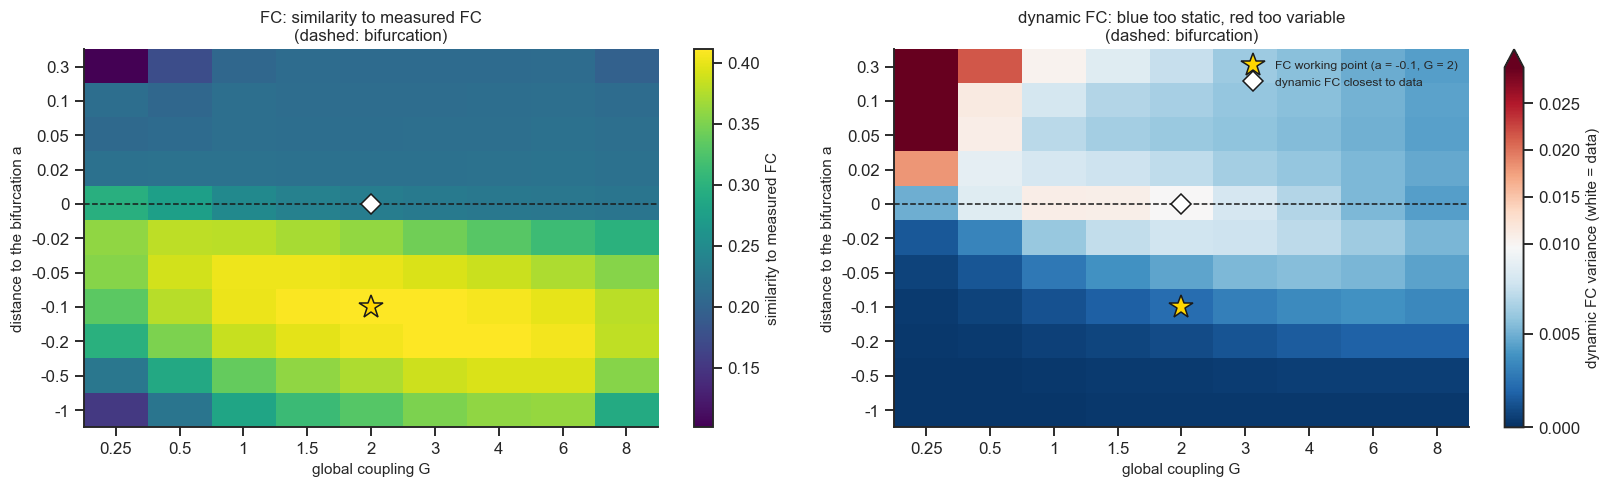

highest FC similarity: 0.411 at a = -0.2, G = 4
FC working point: a = -0.1, G = 2, similarity 0.411, dynamic FC variance 0.0023
dynamic FC closest to data: a = 0, G = 2, variance 0.0098 (data 0.0096), FC similarity 0.23


In [2]:
# @title Sweep a and G: FC similarity and dynamic FC variance (about a minute)
A_list = np.r_[-1.0, -0.5, -0.2, -0.1, -0.05, -0.02, 0.0, 0.02, 0.05, 0.1, 0.3]
G_list = np.r_[0.25, 0.5, 1, 1.5, 2, 3, 4, 6, 8]
fit = np.array([[similarity(model_fc(a, G), fc) for G in G_list] for a in A_list])
dvar = np.array([[np.concatenate([dynamic_fc(x)[1] for x in model_runs(a, G)]).var() for G in G_list] for a in A_list])

i_max = np.unravel_index(np.argmax(fit), fit.shape)                             # highest FC similarity on the grid
i_fc = (list(A_list).index(-0.1), list(G_list).index(2.0))                       # working point used in NB12-NB14 (ties the max)
i_dyn = np.unravel_index(np.argmin(np.abs(np.log(dvar / dfc_data.var()))), dvar.shape)   # dynamic FC closest to data
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
im = ax[0].imshow(fit, origin="lower", aspect="auto", cmap="viridis")
plt.colorbar(im, ax=ax[0], label="similarity to measured FC")
im = ax[1].imshow(dvar, origin="lower", aspect="auto", cmap="RdBu_r",
                  norm=TwoSlopeNorm(vcenter=dfc_data.var(), vmin=0, vmax=3 * dfc_data.var()))
plt.colorbar(im, ax=ax[1], label="dynamic FC variance (white = data)", extend="max")
for a_, title in zip(ax, ["FC: similarity to measured FC", "dynamic FC: blue too static, red too variable"]):
    a_.set_xticks(range(len(G_list)), [f"{g:g}" for g in G_list]); a_.set_yticks(range(len(A_list)), [f"{a:g}" for a in A_list])
    a_.axhline(list(A_list).index(0.0), c="k", ls="--", lw=1)
    a_.plot(i_fc[1], i_fc[0], "*", c="gold", mec="k", ms=16, label="FC working point (a = -0.1, G = 2)")
    a_.plot(i_dyn[1], i_dyn[0], "D", c="w", mec="k", ms=9, label="dynamic FC closest to data")
    a_.set(xlabel="global coupling G", ylabel="distance to the bifurcation a", title=title + "\n(dashed: bifurcation)")
ax[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()
a_fc, G_fc = A_list[i_fc[0]], G_list[i_fc[1]]; a_dyn, G_dyn = A_list[i_dyn[0]], G_list[i_dyn[1]]
print(f"highest FC similarity: {fit[i_max]:.3f} at a = {A_list[i_max[0]]:g}, G = {G_list[i_max[1]]:g}")
print(f"FC working point: a = {a_fc:g}, G = {G_fc:g}, similarity {fit[i_fc]:.3f}, dynamic FC variance {dvar[i_fc]:.4f}")
print(f"dynamic FC closest to data: a = {a_dyn:g}, G = {G_dyn:g}, variance {dvar[i_dyn]:.4f} (data {dfc_data.var():.4f}), FC similarity {fit[i_dyn]:.2f}")

* **FC (left):** the best fit is **below the bifurcation**, in a broad band from $a\approx-0.5$ to $-0.05$ with a
  suitable $G$ (about 0.4). At and beyond the bifurcation the regions lock and the fit drops, whatever the coupling.
  We take $a=-0.1$, $G=2$ (star; as good as the best grid point) as the working point used in the next notebooks.
* **Dynamic FC (right):** far below the bifurcation the model is too **static** (blue): every minute looks alike.
  The variability grows as $a$ approaches 0 and matches the data (white, diamond) only **at the bifurcation**.
  Beyond it, with weak coupling, the regions are independent clocks and the variability overshoots (red).
* A trade-off: at the bifurcation itself the FC fit has already dropped (see the printed numbers). Average FC prefers
  regions a little below the bifurcation, dynamic FC prefers them right at it: in both cases the working point is
  **close to the bifurcation**, never far from it (Deco et al. 2017).

## 2. FC at the working point

> **Gist.** The model FC at the working point next to the measured FC, sorted by network.

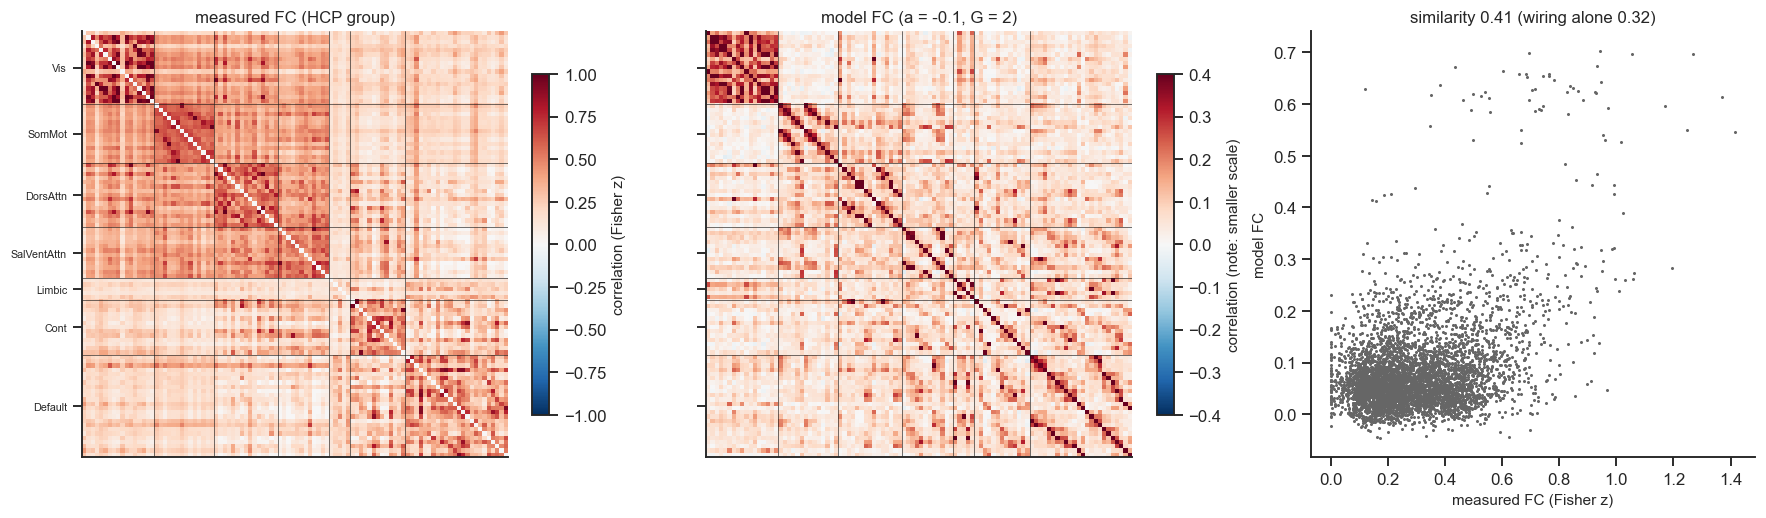

In [3]:
# @title Model FC at the working point vs measured FC
M = model_fc(a_fc, G_fc)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 0.9]), layout="constrained")
show_matrix(ax[0], fc, "measured FC (HCP group)", cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(ax[0].images[0], ax=ax[0], shrink=0.8, label="correlation (Fisher z)")
im = show_matrix(ax[1], M, f"model FC (a = {a_fc:g}, G = {G_fc:g})", labels_on=False, cmap="RdBu_r", vmin=-0.4, vmax=0.4)
plt.colorbar(im, ax=ax[1], shrink=0.8, label="correlation (note: smaller scale)")
ax[2].plot(fc[u], M[u], ".", ms=2, c="0.4")
ax[2].set(xlabel="measured FC (Fisher z)", ylabel="model FC", title=f"similarity {similarity(M, fc):.2f} (wiring alone 0.32)")
plt.show()

Model correlations are weaker overall (note the colour scale): the similarity measures the pattern, not the size.
The model recovers the visual block and the strongest direct and mirror links (the separate cloud top right), but
misses most of the blocks of the association networks: with every region identical the fit stays around 0.4
(regions that differ: NB13b).

## 3. Dynamic FC: the two working points

> **Gist.** The dynamic FC of one person, and of the model at the FC working point and at the point closest to the
> data's dynamic FC (each model run as long as a recording).

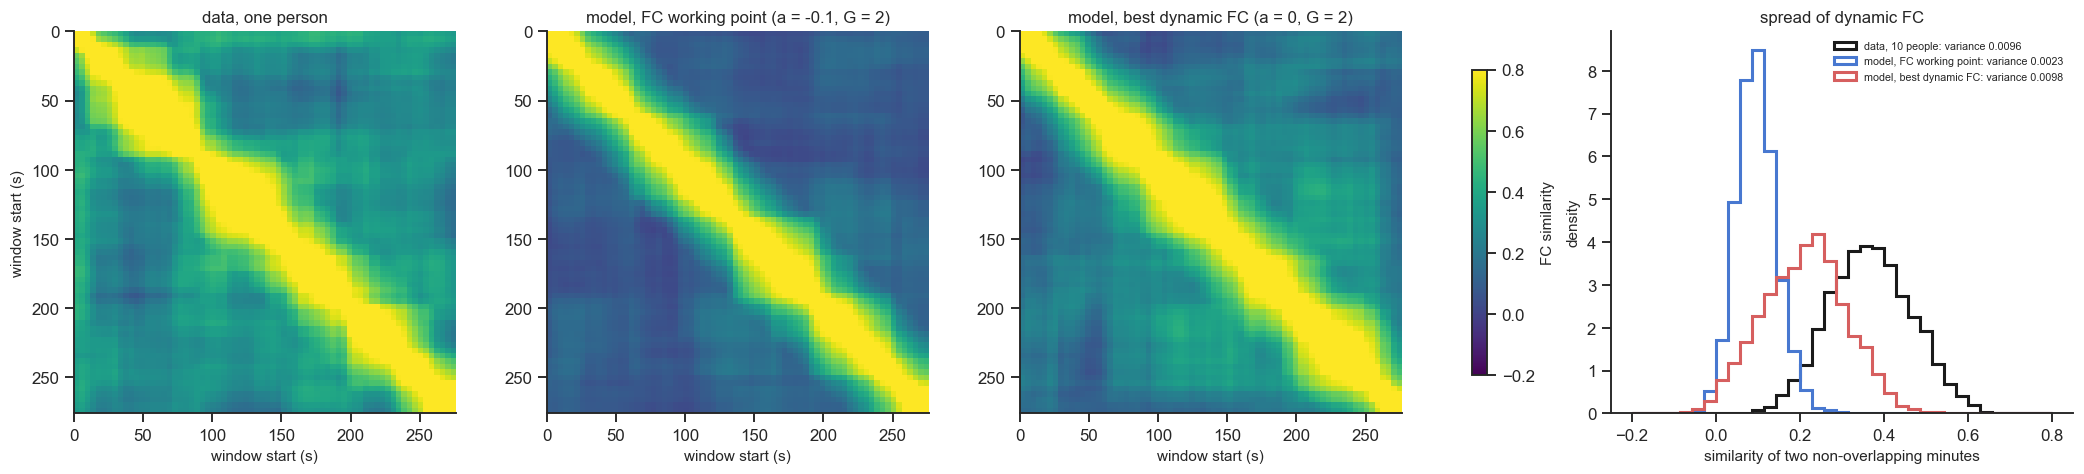

In [4]:
# @title Dynamic FC matrices and distributions: data vs the two model working points
runs_fc, runs_dyn = model_runs(a_fc, G_fc), model_runs(a_dyn, G_dyn)
cases = [("data, one person", ts[0], None, "k"),
         (f"model, FC working point (a = {a_fc:g}, G = {G_fc:g})", runs_fc[0], runs_fc, "C0"),
         (f"model, best dynamic FC (a = {a_dyn:g}, G = {G_dyn:g})", runs_dyn[0], runs_dyn, "C3")]
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2), layout="constrained")
tmax = (len(dynamic_fc(ts[0])[0]) - 1) * 4
for a_, (name, x, runs, c) in zip(ax[:3], cases):
    im = a_.imshow(dynamic_fc(x)[0], cmap="viridis", vmin=-0.2, vmax=0.8, extent=[0, tmax, tmax, 0])
    a_.set(xlabel="window start (s)", ylabel="window start (s)" if a_ is ax[0] else "", title=name)
    vals = dfc_data if runs is None else np.concatenate([dynamic_fc(y)[1] for y in runs])
    ax[3].hist(vals, bins=np.linspace(-0.2, 0.8, 36), density=True, histtype="step", lw=2, color=c,
               label=f"{name.split(' (')[0].replace(', one person', ', 10 people')}: variance {vals.var():.4f}")
plt.colorbar(im, ax=ax[:3], shrink=0.8, label="FC similarity")
ax[3].set(xlabel="similarity of two non-overlapping minutes", ylabel="density", title="spread of dynamic FC")
ax[3].legend(fontsize=7, loc="upper right")
plt.show()

At the FC working point the model's minutes are almost interchangeable: no structure off the diagonal, a narrow
distribution. Closer to the bifurcation the model's FC drifts from minute to minute and the spread approaches the
data's. The distributions are shifted, though: in the data separate minutes are more alike on average.

<details><summary>Why the data's minutes are more alike (caveats)</summary>

The recordings are from people watching a film, and the global signal was not removed (NB09): a shared component
makes all windows look partly alike. A single homogeneous Hopf model has no such component. Comparing whole
distributions (e.g. with a Kolmogorov–Smirnov distance) would therefore reward models that are correlated for other
reasons; here we compare only the spread (variance), as in NB09 and NB11. With 5.6 minutes per person, part of the
spread is sampling noise.
</details>

## 4. Take-home

* The Hopf model beats the wiring alone (0.32 → about 0.4) when regions sit **below their bifurcation**; working
  point for the next notebooks: $a=-0.1$, $G=2$.
* Average FC accepts a broad band of $a$; **dynamic FC** is reproduced only **close to the bifurcation**. Far below, the
  brain model is too static; beyond, regions become clocks.
* The bifurcations of Chapter 4 set the working point of the whole brain.
* **Next:** NB11, regions made of spiking neurons with up and down states, a mechanism for dynamic FC; then NB12
  (the wiring) and NB13b (regions that differ).

### Homework
*To do at home, after the class.*
1. **Whole distributions.** Compare model and data dynamic FC with `scipy.stats.ks_2samp` instead of the variance.
   Which $a$ wins now? Why (see the caveats)?
2. **Longer recordings.** At the two working points, compute the dynamic FC variance from runs of 20 minutes instead of
   5.6. Does it change? What does that say about short recordings?
3. **Frequencies.** Give each region its own frequency `f` (between 0.03 and 0.07 Hz, at random) in
   `wholebrain.hopf_network`. Does the best working point move?

### References
* Deco G, Kringelbach ML, Jirsa VK, Ritter P (2017). The dynamics of resting fluctuations in the brain: metastability and
  its dynamical cortical core. *Sci Rep* 7:3095.
* Hansen ECA, Battaglia D, Spiegler A, Deco G, Jirsa VK (2015). Functional connectivity dynamics: modeling the switching
  behavior of the resting state. *NeuroImage* 105:525–535.
* Honey CJ et al. (2009). Predicting human resting-state functional connectivity from structural connectivity. *PNAS*
  106:2035–2040.